outlier detection and tretment

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
data={
    "Student":["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O"],
"Study_hours" :[2,2,4,6,4,5,2,3,4,3,4,2,4,30,3]
}
df=pd.DataFrame(data)
print("Original Dataset")
print(df)

Original Dataset
   Student  Study_hours
0        A            2
1        B            2
2        C            4
3        D            6
4        E            4
5        F            5
6        G            2
7        H            3
8        I            4
9        J            3
10       K            4
11       L            2
12       M            4
13       N           30
14       O            3


describe

In [ ]:
df["Study_hours"].describe()

,Study_hours
count,15.000000
mean,5.200000
std,6.961116
min,2.000000
25%,2.500000
50%,4.000000
75%,4.000000
max,30.000000


visualisation

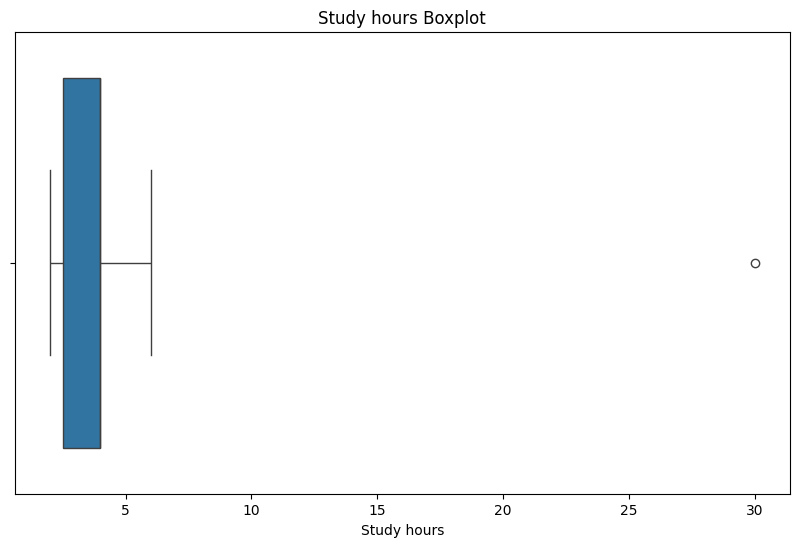

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(x=df["Study_hours"])
plt.title("Study hours Boxplot")
plt.xlabel("Study hours")
plt.show()

IQR method
STEP1-find Q1,Q3
Q1-25%
Q2-75%

In [ ]:
Q1=df['Study_hours'].quantile(0.25)
Q3=df['Study_hours'].quantile(0.75)
print("Q1",Q1)
print("Q3",Q3)

Q1 2.5
Q3 4.0


STEP2-calculate IQR(Inter quantile range)

In [ ]:
IQR=Q3-Q1
print("IQR:",IQR)

IQR: 1.5


STEP3-CALCULATE BOUNDRIES

In [ ]:
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print("Lower bound:",lower_bound)
print("Upper bound:",upper_bound)

Lower bound: 0.25
Upper bound: 6.25


identify the outlier

In [ ]:
outlier_iqr=df[
    (df["Study_hours"]<lower_bound)|(df["Study_hours"]>upper_bound)]
print("Outliers using IQR method:")
print(outlier_iqr)

Outliers using IQR method:
   Student  Study_hours
13       N           30


Non outlier data

In [ ]:
normal_data_iqr=df[
    (df["Study_hours"]>=lower_bound)&(df["Study_hours"]<=upper_bound)]
print("Non outlier data using IQR method:")
print(normal_data_iqr)


Non outlier data using IQR method:
   Student  Study_hours
0        A            2
1        B            2
2        C            4
3        D            6
4        E            4
5        F            5
6        G            2
7        H            3
8        I            4
9        J            3
10       K            4
11       L            2
12       M            4
14       O            3


Z-score method


In [ ]:
df["z_score"]=zscore(df["Study_hours"])
print("Dataset with z-scores")
print(df)

Dataset with z-scores
   Student  Study_hours   z_score
0        A            2 -0.475831
1        B            2 -0.475831
2        C            4 -0.178437
3        D            6  0.118958
4        E            4 -0.178437
5        F            5 -0.029739
6        G            2 -0.475831
7        H            3 -0.327134
8        I            4 -0.178437
9        J            3 -0.327134
10       K            4 -0.178437
11       L            2 -0.475831
12       M            4 -0.178437
13       N           30  3.687690
14       O            3 -0.327134


In [ ]:
z_outliers=df[
    (df["z_score"]>3)|(df["z_score"]<-3)]
print("Outliers using Z-score method:")
print(z_outliers)

Outliers using Z-score method:
   Student  Study_hours  z_score
13       N           30  3.68769


compair both outlier

In [ ]:
display(outlier_iqr)
display(z_outliers)

,Student,Study_hours
13,N,30


,Student,Study_hours,z_score
13,N,30,3.68769


Treatment1-remove iqr outliers

In [ ]:
df_without_outliers=df[
    (df["Study_hours"]>=lower_bound)&(df["Study_hours"]<=upper_bound)]
print("Dataset without IQR outliers:")
print(df_without_outliers)

Dataset without IQR outliers:
   Student  Study_hours   z_score
0        A            2 -0.475831
1        B            2 -0.475831
2        C            4 -0.178437
3        D            6  0.118958
4        E            4 -0.178437
5        F            5 -0.029739
6        G            2 -0.475831
7        H            3 -0.327134
8        I            4 -0.178437
9        J            3 -0.327134
10       K            4 -0.178437
11       L            2 -0.475831
12       M            4 -0.178437
14       O            3 -0.327134


Treatment2-Capping (replace with boundary value)

In [ ]:
df_capped=df.copy()
df_capped["Study_hours"]=df_capped['Study_hours'].clip(lower_bound,upper_bound)
df_capped


,Student,Study_hours,z_score
0,A,2.00,-0.475831
1,B,2.00,-0.475831
2,C,4.00,-0.178437
3,D,6.00,0.118958
4,E,4.00,-0.178437
5,F,5.00,-0.029739
6,G,2.00,-0.475831
7,H,3.00,-0.327134
8,I,4.00,-0.178437
9,J,3.00,-0.327134


compair earlier and now data

In [ ]:
print("Original data")
print(df)
print("using IQR")
print(df_without_outliers)
print("using Capping")
print(df_capped)

Original data
   Student  Study_hours   z_score
0        A            2 -0.475831
1        B            2 -0.475831
2        C            4 -0.178437
3        D            6  0.118958
4        E            4 -0.178437
5        F            5 -0.029739
6        G            2 -0.475831
7        H            3 -0.327134
8        I            4 -0.178437
9        J            3 -0.327134
10       K            4 -0.178437
11       L            2 -0.475831
12       M            4 -0.178437
13       N           30  3.687690
14       O            3 -0.327134
using IQR
   Student  Study_hours   z_score
0        A            2 -0.475831
1        B            2 -0.475831
2        C            4 -0.178437
3        D            6  0.118958
4        E            4 -0.178437
5        F            5 -0.029739
6        G            2 -0.475831
7        H            3 -0.327134
8        I            4 -0.178437
9        J            3 -0.327134
10       K            4 -0.178437
11       L            2 

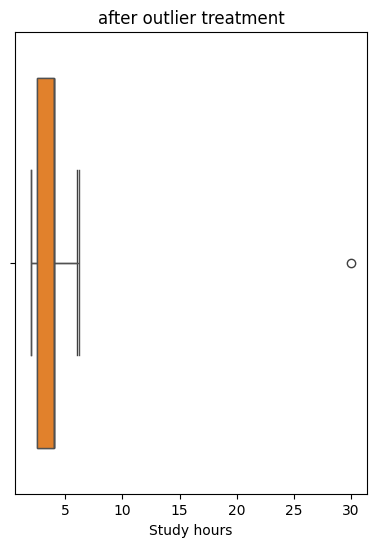

In [ ]:
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
sns.boxplot(x=df["Study_hours"])
plt.title("before outlier treatment")
plt.xlabel("Study hours")
plt.subplot(1,2,1)
sns.boxplot(x=df_capped["Study_hours"])
plt.title("after outlier treatment")
plt.xlabel("Study hours")
plt.show()
plt.show()